<a href="https://colab.research.google.com/github/karthick-2008/DSA0404-Fundamental-Of-Data-Science/blob/main/Q.NO_23.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving Book2 23.xlsx to Book2 23.xlsx
Clinical Trial Dataset:
  Patient_ID    Group  Baseline_Score  Post_Treatment_Score  Improvement
0     PT-001  Placebo            84.9                  65.2         19.7
1     PT-002  Placebo            74.5                  79.4         -4.9
2     PT-003  Placebo            77.9                  81.2         -3.3
3     PT-004  Placebo            73.5                  71.3          2.2
4     PT-005  Placebo            81.5                  84.4         -2.9

Group Analysis:
Placebo Mean: 2.62
Treatment Mean: 14.53

Hypothesis Testing:
T-Statistic: 4.4092
P-Value: 3.282447371280714e-05

Result: Reject Null Hypothesis
There is a statistically significant difference.


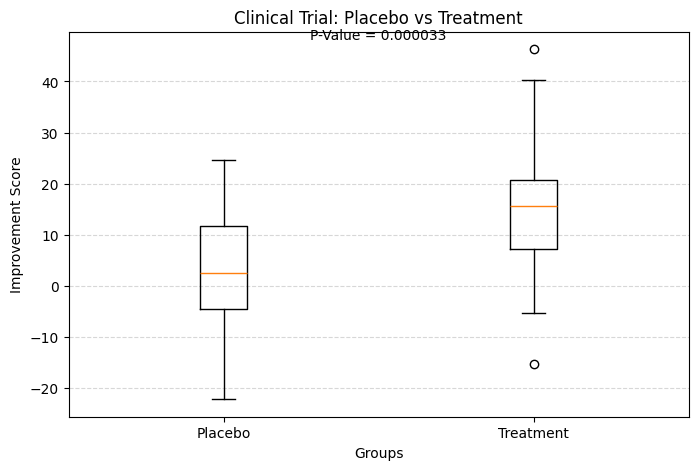

In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from google.colab import files

# Upload Excel dataset
uploaded = files.upload()

# Read dataset
df = pd.read_excel('Book2 23.xlsx')

print("Clinical Trial Dataset:")
print(df.head())

# Separate the two groups
placebo = df[df['Group'] == 'Placebo']['Improvement']
treatment = df[df['Group'] == 'Treatment']['Improvement']

# Calculate mean improvement
placebo_mean = placebo.mean()
treatment_mean = treatment.mean()

print("\nGroup Analysis:")
print("Placebo Mean:", round(placebo_mean, 2))
print("Treatment Mean:", round(treatment_mean, 2))

# Hypothesis Testing
# H0: There is no significant difference
# H1: There is a significant difference

t_stat, p_value = stats.ttest_ind(
    treatment, placebo, equal_var=False
)

print("\nHypothesis Testing:")
print("T-Statistic:", round(t_stat, 4))
print("P-Value:", p_value)

# Decision
alpha = 0.05

if p_value < alpha:
    print("\nResult: Reject Null Hypothesis")
    print("There is a statistically significant difference.")
else:
    print("\nResult: Accept Null Hypothesis")
    print("There is no statistically significant difference.")

# Visualization
plt.figure(figsize=(8, 5))

plt.boxplot(
    [placebo, treatment],
    tick_labels=['Placebo', 'Treatment']
)

plt.title('Clinical Trial: Placebo vs Treatment')
plt.ylabel('Improvement Score')
plt.xlabel('Groups')

plt.text(
    1.5,
    max(df['Improvement']) + 2,
    f'P-Value = {p_value:.6f}',
    ha='center'
)

plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()
